# Exploratory B: ARMA(1,1) mean per factor (slow latent drift)

*Exploratory notebook, not part of the roadmap.*

**Question.** The daily factor scores have almost no autocorrelation, yet their 250-day variance ratio is 1.5-2.6. A persistent drift hidden in noise, which an ARMA(1,1) can represent, would produce exactly that. Does it improve the horizon distribution?

**Method.** One ARMA(1,1) per factor (`s_t = phi s_(t-1) + e_t + theta e_(t-1)`), fitted on the scores scaled by 100 from two starting points, fast (0.25, -0.2) and slow drift (0.98, -0.96). Two models are compared: the higher-likelihood fit, and the slow-drift fit for all factors. Cross-factor VAR terms are dropped (the M2 off-diagonals are small, except PC2 on PC3).

Only the mean dynamics change: shocks are M2's constant-sigma Student-t (fitted on each model's residuals), so differences from M2 are due to the mean. Same checks as `06_garch.ipynb`: variance ratio, Design A, Design B.

In [1]:
%load_ext autoreload
%autoreload 2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import TwoSlopeNorm
from scipy import stats
from scenario_lab.data import load_curve
from scenario_lab.models import var1 as m
from scenario_lab import validation as v
plt.style.use("default"); plt.rcParams["figure.facecolor"] = "white"

levels = load_curve("AAA")
changes = levels.diff().dropna()
realised = v.realised_changes(levels)
FIT_END = v.FIT_END
mats = list(levels.columns)

def shock_params(resid):
    """Constant-sigma Student-t shocks as in M2: per-factor std and df (floored at m.MIN_DF)."""
    sigma = resid.std(axis=0)
    df = np.maximum([stats.t.fit(resid[:, j] / sigma[j], floc=0)[0] for j in range(resid.shape[1])], m.MIN_DF)
    return sigma, np.array(df)

def draw_eps(sigma, df, n_paths, n_days, rng):
    k = len(sigma)
    return sigma * np.sqrt((df - 2) / df) * stats.t.rvs(df, size=(n_paths, n_days, k), random_state=rng)

def curves_from_scores(S, V, y0):
    """S: (n_paths, n_days, k) factor changes -> curves (n_paths, n_days + 1, n_mats)."""
    dy = S @ V.T
    y0 = np.asarray(y0)
    return np.concatenate([np.broadcast_to(y0, (S.shape[0], 1, y0.size)), y0 + np.cumsum(dy, axis=1)], axis=1)

## Model definitions

In [2]:
import warnings
from statsmodels.tsa.arima.model import ARIMA

SC = 100.0     # fit on scores x100: at the raw scale (variance ~0.01) the optimiser failed to converge

def _arma_one(x, force_slow):
    """ARMA(1,1) without constant on x (scaled). Two starts: fast (0.25, -0.2) and slow drift (0.98, -0.96).
    Keep the higher likelihood, or the slow one if force_slow. Returns (phi, theta, resid)."""
    v = x.var()
    fits = []
    for sp in ([0.98, -0.96, v],) if force_slow else ([0.25, -0.2, v], [0.98, -0.96, v]):
        with warnings.catch_warnings():
            warnings.simplefilter("ignore")
            fits.append(ARIMA(x, order=(1, 0, 1), trend="n").fit(start_params=sp))
    f = max(fits, key=lambda r: r.llf)
    return f.params[0], f.params[1], f.resid

def fit_arma(changes, k=3, force_slow=False):
    """Independent ARMA(1,1) per factor on the PCA scores: s_t = phi s_{t-1} + e_t + theta e_{t-1}.
    phi near 1 with theta near -phi: tiny short-lag autocorrelation but a large long-horizon variance ratio."""
    base = m.fit(changes, k)
    s = changes.values @ base.V * SC
    out = [_arma_one(s[:, j], force_slow) for j in range(k)]
    phi = np.array([o[0] for o in out]); theta = np.array([o[1] for o in out])
    sigma, df = shock_params(np.column_stack([o[2] for o in out]) / SC)
    return dict(V=base.V, phi=phi, theta=theta, sigma=sigma, df=df)

def simulate_arma(q, y0, n_paths=m.N_PATHS, n_days=m.N_DAYS, seed=0):
    rng = np.random.default_rng(seed)
    k = len(q["phi"])
    eps = draw_eps(q["sigma"], q["df"], n_paths, n_days, rng)
    s_prev = np.zeros((n_paths, k)); e_prev = np.zeros((n_paths, k))
    S = np.empty((n_paths, n_days, k))
    for t in range(n_days):
        s_prev = q["phi"] * s_prev + eps[:, t] + q["theta"] * e_prev
        e_prev = eps[:, t]
        S[:, t] = s_prev
    return curves_from_scores(S, q["V"], y0)

In [3]:
models = {"M2 (VAR1)": (m.fit, m.simulate),
          "ARMA best-llf": (fit_arma, simulate_arma),
          "ARMA slow": (lambda ch: fit_arma(ch, force_slow=True), simulate_arma)}
for name, kw in [("best-llf", {}), ("slow", {"force_slow": True})]:
    qa = fit_arma(changes, **kw)
    print(f"{name}: phi {qa['phi'].round(3)} theta {qa['theta'].round(3)} sigma {qa['sigma'].round(4)} df {qa['df'].round(1)}")

best-llf: phi [0.488 0.24  0.991] theta [-0.457 -0.151 -0.983] sigma [0.0872 0.0378 0.0189] df [4.3 3.3 3. ]


slow: phi [0.995 0.986 0.991] theta [-0.992 -0.976 -0.983] sigma [0.0873 0.0379 0.0189] df [4.2 3.2 3. ]


## Variance ratio and horizon std (full-sample fit, from today's curve)

Realised `var(250d) / (250 * var(daily))` is 5.7 (1Y), 2.5 (2Y), 1.4 (5Y), 1.2 (10Y), 1.1 (20Y), 0.9 (30Y); M2 gives about 1.1 throughout. A mean model that closes the horizon gap has to move the simulated ratio towards these values.

In [4]:
y0 = levels.iloc[-1].values
fitted = {k: fit(changes) for k, (fit, sim) in models.items()}
curves = {k: models[k][1](fitted[k], y0, seed=0) for k in models}

vr_real = realised.var() / (250 * changes.var())
vr = pd.DataFrame({"realised": vr_real, **{k: pd.Series((c[:, -1] - y0).var(0) / (250 * np.diff(c, axis=1).reshape(-1, 6).var(0)), index=mats)
                                          for k, c in curves.items()}})
print("variance ratio var(250d) / (250 * var(daily))")
print(vr.round(2))
print("\nstd of the 250-day change (pp)")
print(pd.DataFrame({"realised 250d": realised.std().values, **{k: (c[:, -1] - y0).std(0) for k, c in curves.items()}}, index=mats).round(3))

variance ratio var(250d) / (250 * var(daily))
     realised  M2 (VAR1)  ARMA best-llf  ARMA slow
1Y       5.68       1.14           1.33       1.86
2Y       2.45       1.11           1.18       1.72
5Y       1.39       1.04           1.17       1.59
10Y      1.20       1.04           1.20       1.55
20Y      1.07       1.09           1.14       1.57
30Y      0.88       1.10           1.20       1.66

std of the 250-day change (pp)
     realised 250d  M2 (VAR1)  ARMA best-llf  ARMA slow
1Y           1.056      0.459          0.495      0.585
2Y           0.935      0.623          0.645      0.776
5Y           0.763      0.653          0.694      0.808
10Y          0.711      0.658          0.704      0.803
20Y          0.707      0.707          0.721      0.847
30Y          0.696      0.775          0.807      0.951


## Design A: single cut (end-2018)

In [5]:
y0_a = levels.loc[:FIT_END].iloc[-1].values
sims_a = {}
for k, (fit, sim) in models.items():
    c = sim(fit(changes.loc[:FIT_END]), y0_a, seed=0)
    sims_a[k] = c[:, -1] - c[:, 0]
test = realised.loc[FIT_END:]
for band, (lo, hi), nom in [("5-95%", (0.05, 0.95), 0.9), ("25-75%", (0.25, 0.75), 0.5)]:
    print(f"coverage {band} on test windows (nominal {nom:.0%})")
    print(pd.DataFrame({k: v.coverage(s, test, lo, hi) for k, s in sims_a.items()}).round(3), "\n")

coverage 5-95% on test windows (nominal 90%)
     M2 (VAR1)  ARMA best-llf  ARMA slow
1Y       0.563          0.565      0.583
2Y       0.708          0.708      0.728
5Y       0.789          0.794      0.802
10Y      0.811          0.817      0.827
20Y      0.840          0.838      0.848
30Y      0.885          0.885      0.895 

coverage 25-75% on test windows (nominal 50%)
     M2 (VAR1)  ARMA best-llf  ARMA slow
1Y       0.397          0.399      0.402
2Y       0.494          0.492      0.498
5Y       0.573          0.580      0.599
10Y      0.544          0.573      0.615
20Y      0.536          0.524      0.560
30Y      0.580          0.573      0.605 



## Design B: expanding window (origins 2012-2022)

In [6]:
origins = [f"{y}-12-31" for y in range(2012, 2023)]
c90 = {k: {} for k in models}; c50 = {k: {} for k in models}
for o in origins:
    ch_o, y0_o = changes.loc[:o], levels.loc[:o].iloc[-1].values
    test_o = realised[realised.index > o].iloc[:250]
    for k, (fit, sim) in models.items():
        cv = sim(fit(ch_o), y0_o)
        s = cv[:, -1] - cv[:, 0]
        c90[k][o] = v.coverage(s, test_o, 0.05, 0.95); c50[k][o] = v.coverage(s, test_o, 0.25, 0.75)
t90 = {k: pd.DataFrame(v).T for k, v in c90.items()}
t50 = {k: pd.DataFrame(v).T for k, v in c50.items()}
print("pooled 5-95% coverage by maturity (nominal 0.90)")
print(pd.DataFrame({k: t.mean() for k, t in t90.items()}).T.round(3))
print("\nmean |coverage - nominal|, all origins and maturities")
print(pd.DataFrame({"5-95%": {k: (t90[k] - 0.9).abs().values.mean() for k in t90},
                    "25-75%": {k: (t50[k] - 0.5).abs().values.mean() for k in t50}}).round(3))

pooled 5-95% coverage by maturity (nominal 0.90)
                  1Y     2Y     5Y    10Y    20Y    30Y
M2 (VAR1)      0.831  0.853  0.870  0.822  0.842  0.896
ARMA best-llf  0.833  0.854  0.872  0.841  0.836  0.899
ARMA slow      0.839  0.863  0.874  0.855  0.861  0.912

mean |coverage - nominal|, all origins and maturities
               5-95%  25-75%
M2 (VAR1)      0.185   0.321
ARMA best-llf  0.182   0.320
ARMA slow      0.183   0.333


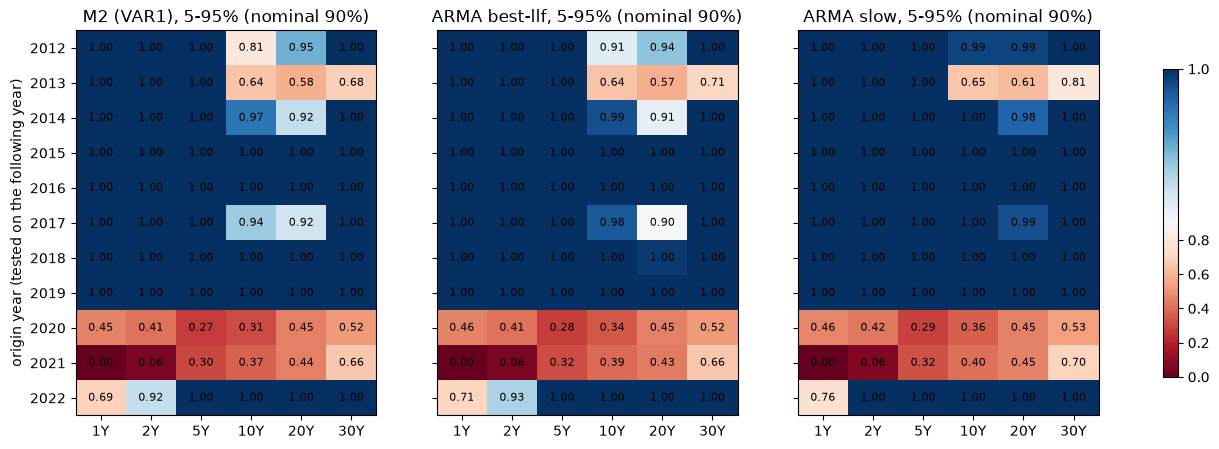

In [7]:
def heat(ax, tab, nominal, title):
    im = ax.imshow(tab.values, cmap="RdBu", norm=TwoSlopeNorm(vcenter=nominal, vmin=0, vmax=1), aspect="auto")
    ax.set_xticks(range(tab.shape[1])); ax.set_xticklabels(tab.columns)
    ax.set_yticks(range(tab.shape[0])); ax.set_yticklabels([o[:4] for o in tab.index])
    for i in range(tab.shape[0]):
        for j in range(tab.shape[1]):
            ax.text(j, i, f"{tab.values[i, j]:.2f}", ha="center", va="center", fontsize=8)
    ax.set_title(title); return im

fig, axes = plt.subplots(1, len(t90), figsize=(5.5 * len(t90), 5), sharey=True)
for ax, (k, t) in zip(np.atleast_1d(axes), t90.items()):
    im = heat(ax, t, 0.9, f"{k}, 5-95% (nominal 90%)")
np.atleast_1d(axes)[0].set_ylabel("origin year (tested on the following year)")
fig.colorbar(im, ax=axes, shrink=0.8); plt.show()

## Results

- **Fit.** The likelihood prefers the slow drift only for PC3 (phi 0.99, theta -0.98); PC1 and PC2 prefer fast solutions (phi 0.49, 0.24). The slow solutions are only 2 (PC1) and 15 (PC2) log-likelihood points lower, so they are not clearly rejected.
- **Variance ratio.** The slow drift raises the ratio at every maturity together: 1Y from 1.14 to 1.86 (realised 5.7), but also 30Y from 1.10 to 1.66 (realised 0.9). The best-likelihood fit moves it much less (1Y 1.33).
- **Coverage.** Design B mean |coverage - nominal| for the 5-95% band is 0.182 (best-likelihood) and 0.183 (slow) against 0.185 for M2; the 25-75% band is worse with the slow drift (0.333 against 0.321). Design A test coverage changes by 1-3 points.

**Conclusion.** A per-factor drift does not recover the short-end trending: it raises the variance ratio at all maturities, so the long end overshoots, and coverage does not improve. Together with `a_var_lags`, adding linear time-series structure to the PCA factors does not close the horizon gap. A short-end-specific or level-dependent mechanism would be needed; this was not tested.